# 3 相似度加權平均：2 × 2 × 2 比較

```
P(u,i) = ( Σ_j w_uij · y_uj + α · p_u ) / ( Σ_j w_uij + α ),   w_uij = Sim(i,j) · exp(−λ · Δyears)
```
j 為 user 歷史中與 i 最相似的前 k 道。比較 **Jaccard／Cosine × tags／ingredients × 有無時間衰減**（λ = 0 或 λ > 0）。

讀取 `BETA`、`MAX_DF`；在 validation cold 列選每個版本的 k、α、λ，存成 `WA`。

- **AUC**（不同 user 的評論互相比較）：知道誰比較大方就能拿高分，所以 B1 很強。用**配對 bootstrap** 檢查每個版本比 B1 好多少、是否顯著。
- **Hit@10／NDCG@10**（同一個 user 的 100 道新食譜互相比較）：B1 給每道食譜同一個分數，等於隨機（0.10），只有內容相似度能拉開差距。

In [1]:
%load_ext autoreload
%autoreload 2

import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import *
from features import (RecipeSets, build_features, group_columns, load_interactions, load_recipes,
                      make_snapshot, user_prior, weighted_average, year_snapshot)
from models import (VARIANTS, baseline_constant, fit_lr, lr_coefficients, predict, training_set,
                    tune_beta, tune_weighted_average)
from evaluation import auc, compare, evaluate, mean_ci, pretty
from ranking import ranking_metrics, sample_candidates

warnings.filterwarnings("ignore", category=FutureWarning)  # pandas copy-on-write notices
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.4f}".format)

In [2]:
t0 = time.time()
train, val, test = load_interactions()
recipes = load_recipes()
print(f"loaded in {time.time() - t0:.0f}s: train {len(train):,}, validation {len(val):,}, test {len(test):,}, recipes {len(recipes):,}")

loaded in 8s: train 683,996, validation 22,933, test 22,224, recipes 178,265


In [3]:
P = load_params("BETA", "MAX_DF")
BETA, MAX_DF = P["BETA"], P["MAX_DF"]

rsets = RecipeSets(recipes)
snap_val = make_snapshot("validation", train, val, rsets, H=H, max_df=MAX_DF)
cold_val = snap_val.targets.cold.values == 1
y_val = snap_val.targets[f"y_{LABEL}"].values
u_val = snap_val.targets.u.values
print(f"validation snapshot: {snap_val.n:,} rows ({cold_val.sum():,} cold), {len(snap_val.pairs):,} pairs")
prior_val = user_prior(snap_val, LABEL, BETA)

validation snapshot: 22,933 rows (6,410 cold), 1,749,741 pairs


In [4]:
WA, tuning = {}, {}
t0 = time.time()
for name, col in VARIANTS.items():
    for suffix, lams in (("", (0.0,)), ("-T", LAMBDA_GRID_T)):
        tbl = tune_weighted_average(snap_val, col, LABEL, prior_val, cold_val, ks=K_GRID, alphas=ALPHA_GRID, lams=lams)
        best = tbl.iloc[0]
        WA[name + suffix] = {"sim": col, "k": int(best.k), "alpha": float(best.alpha), "lam": float(best.lam)}
        tuning[name + suffix] = tbl
print(f"tuned in {time.time() - t0:.0f}s")
save_params(WA=WA)
pd.DataFrame(WA).T

tuned in 14s


,sim,k,alpha,lam
J1,jac_tag,50,5.0000,0.0000
J1-T,jac_tag,50,5.0000,0.0300
J2,jac_ing,50,2.0000,0.0000
J2-T,jac_ing,50,2.0000,0.0300
C1,cos_tag,50,10.0000,0.0000
C1-T,cos_tag,50,10.0000,0.0300
C2,cos_ing,50,5.0000,0.0000
C2-T,cos_ing,50,5.0000,0.0300


In [5]:
def wa_predictions(snap, prior, label=LABEL):
    return {name: weighted_average(snap, prm["sim"], label, prior, prm["k"], prm["alpha"], prm["lam"])
            for name, prm in WA.items()}

def grid_table(res):
    # 2 x 2 x 2: similarity x time decay (rows) by set (columns), AUC
    return pd.DataFrame(
        {("tags" if s == "1" else "ingredients"): {
            f"{'Jaccard' if m == 'J' else 'Cosine'}, {'λ > 0' if d else 'λ = 0'}": res.loc[f"{m}{s}{d}", "AUC"]
            for m in "JC" for d in ("", "-T")}
         for s in "12"})

preds_val = {"B0": baseline_constant(snap_val, LABEL), "B1": prior_val, **wa_predictions(snap_val, prior_val)}
ev = {k: v[cold_val] for k, v in preds_val.items()}
res_wa = evaluate(ev, y_val[cold_val], u_val[cold_val], n_boot=N_BOOT)
res_wa.to_csv(RESULTS / "val_weighted_average.csv")
pretty(res_wa)

,AUC,LogLoss,Brier
model,,,
B0,"0.5000 [0.5000, 0.5000]","0.5331 [0.5046, 0.5637]","0.1743 [0.1613, 0.1881]"
B1,"0.7252 [0.6902, 0.7605]","0.4722 [0.4404, 0.5048]","0.1530 [0.1409, 0.1657]"
J1,"0.7305 [0.6964, 0.7660]","0.4678 [0.4348, 0.5008]","0.1507 [0.1384, 0.1634]"
J1-T,"0.7305 [0.6964, 0.7659]","0.4677 [0.4347, 0.5007]","0.1507 [0.1384, 0.1634]"
J2,"0.7297 [0.6960, 0.7639]","0.4690 [0.4360, 0.5020]","0.1511 [0.1390, 0.1639]"
J2-T,"0.7296 [0.6960, 0.7639]","0.4689 [0.4360, 0.5020]","0.1511 [0.1390, 0.1639]"
C1,"0.7302 [0.6963, 0.7653]","0.4679 [0.4347, 0.5010]","0.1508 [0.1386, 0.1635]"
C1-T,"0.7302 [0.6965, 0.7652]","0.4679 [0.4347, 0.5009]","0.1508 [0.1386, 0.1635]"
C2,"0.7297 [0.6958, 0.7641]","0.4684 [0.4356, 0.5015]","0.1511 [0.1390, 0.1640]"


### 配對 bootstrap：每個版本 − B1（同一批 bootstrap 樣本）

In [6]:
cmp_wa = compare({k: v for k, v in ev.items() if k != "B0"}, "B1", y_val[cold_val], u_val[cold_val], n_boot=N_BOOT)
cmp_wa.to_csv(RESULTS / "val_weighted_average_vs_B1.csv")
pretty(cmp_wa)[["ΔAUC", "p_not_better_AUC", "ΔLogLoss", "p_not_better_LogLoss"]]

,ΔAUC,p_not_better_AUC,ΔLogLoss,p_not_better_LogLoss
model,,,,
J1,"+0.0053 [+0.0000, +0.0113]",0.025,"-0.0044 [-0.0096, -0.0001]",0.022
J1-T,"+0.0053 [+0.0000, +0.0113]",0.025,"-0.0044 [-0.0095, -0.0002]",0.021
J2,"+0.0044 [-0.0017, +0.0109]",0.086,"-0.0032 [-0.0088, +0.0018]",0.126
J2-T,"+0.0044 [-0.0017, +0.0108]",0.086,"-0.0033 [-0.0088, +0.0017]",0.118
C1,"+0.0049 [-0.0001, +0.0105]",0.027,"-0.0042 [-0.0091, -0.0002]",0.022
C1-T,"+0.0049 [-0.0001, +0.0105]",0.027,"-0.0043 [-0.0090, -0.0003]",0.020
C2,"+0.0045 [-0.0009, +0.0104]",0.057,"-0.0038 [-0.0088, +0.0004]",0.049
C2-T,"+0.0044 [-0.0009, +0.0103]",0.057,"-0.0038 [-0.0086, +0.0003]",0.045


In [7]:
print(f"B1 AUC = {res_wa.loc['B1', 'AUC']:.4f}")
grid = grid_table(res_wa)
grid.to_csv(RESULTS / "val_grid_2x2x2.csv")
grid

B1 AUC = 0.7252


,tags,ingredients
"Jaccard, λ = 0",0.7305,0.7297
"Jaccard, λ > 0",0.7305,0.7296
"Cosine, λ = 0",0.7302,0.7297
"Cosine, λ > 0",0.7302,0.7296


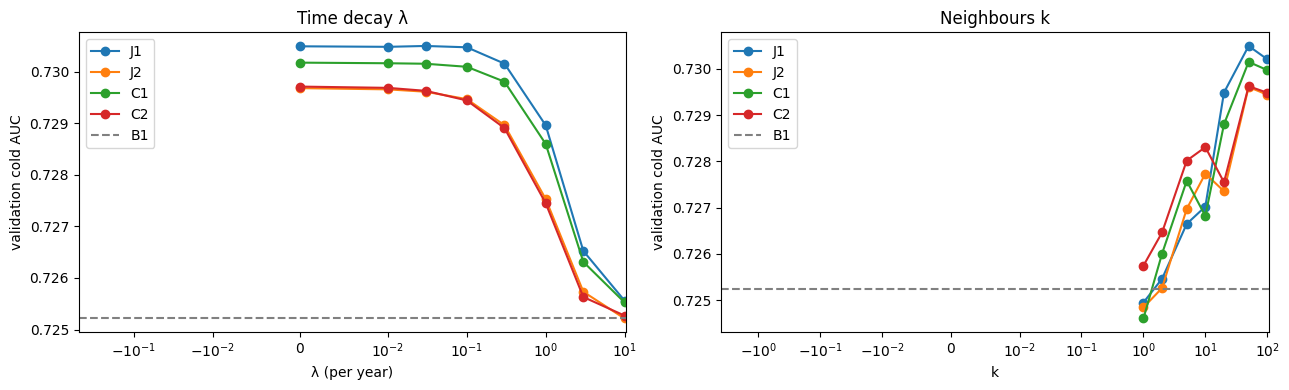

In [8]:
# AUC as a function of lambda and k (other parameters at the tuned -T values)
lam_grid = [0, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]
k_grid = [1, 2, 5, 10, 20, 50, 100]
yc = y_val[cold_val]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, col in VARIANTS.items():
    prm = WA[name + "-T"]
    ax[0].plot(lam_grid, [auc(yc, weighted_average(snap_val, col, LABEL, prior_val, prm["k"], prm["alpha"], l)[cold_val])
                          for l in lam_grid], marker="o", label=name)
    ax[1].plot(k_grid, [auc(yc, weighted_average(snap_val, col, LABEL, prior_val, k, prm["alpha"], prm["lam"])[cold_val])
                        for k in k_grid], marker="o", label=name)
for a in ax:
    a.axhline(res_wa.loc["B1", "AUC"], color="gray", ls="--", label="B1")
    a.set_xscale("symlog", linthresh=0.01); a.set_ylabel("validation cold AUC"); a.legend()
ax[0].set(title="Time decay λ", xlabel="λ (per year)"); ax[1].set(title="Neighbours k", xlabel="k")
plt.tight_layout(); plt.savefig(RESULTS / "lambda_k_curves.png", dpi=150); plt.show()

### 排名：Hit@10／NDCG@10（validation）

每個 list = 一筆 5 分的 cold 評論 + 99 道這個 user 沒評過、在當天已發布、train 中沒有評論的新食譜。
配對差距以 J1 為基準。

In [9]:
reviewed = pd.concat([train, val, test]).groupby("user_id").recipe_id.agg(set).to_dict()

def ranking_lists(history, rows):
    # one list per sampled 5-star cold review: the positive + N_NEG new recipes the user never reviewed
    positives = rows[(rows.cold == 1) & (rows.y_eq5 == 1)]
    cands = sample_candidates(positives, history, recipes, reviewed, n_lists=N_RANK_LISTS, n_neg=N_NEG)
    snap = make_snapshot("candidates", history, cands, rsets, H=H, max_df=MAX_DF)
    assert snap.n == len(cands)
    return cands, snap

def ranking_table(cands, scores, base):
    per = {k: ranking_metrics(cands, s) for k, s in scores.items()}
    users = next(iter(per.values())).user_id.values
    hit = mean_ci({k: v["Hit@10"].values for k, v in per.items()}, users, n_boot=N_BOOT, base=base)
    ndcg = mean_ci({k: v["NDCG@10"].values for k, v in per.items()}, users, n_boot=N_BOOT, base=base)
    return hit, ndcg

t0 = time.time()
cands_val, snap_cv = ranking_lists(train, val)
prior_cv = user_prior(snap_cv, LABEL, BETA)
scores_cv = {"B1": prior_cv, **wa_predictions(snap_cv, prior_cv)}
hit_val, ndcg_val = ranking_table(cands_val, scores_cv, base="J1")
hit_val.to_csv(RESULTS / "val_ranking_hit10.csv"); ndcg_val.to_csv(RESULTS / "val_ranking_ndcg10.csv")
print(f"{cands_val.list_id.nunique():,} lists, {len(snap_cv.pairs):,} pairs, {time.time() - t0:.0f}s")
pd.concat({"Hit@10": pretty(hit_val), "NDCG@10": pretty(ndcg_val)}, axis=1)

1,000 lists, 8,677,600 pairs, 8s


Hit@10                                                           NDCG@10                                         
                          mean                           Δ p_not_better                     mean                           Δ p_not_better
model                                                                                                                                    
B1     0.1000 [0.1000, 0.1000]  -0.0310 [-0.0553, -0.0085]        0.997  0.0454 [0.0454, 0.0454]  -0.0216 [-0.0353, -0.0091]        0.999
J1     0.1310 [0.1085, 0.1553]           +nan [+nan, +nan]          nan  0.0670 [0.0545, 0.0808]           +nan [+nan, +nan]          nan
J1-T   0.1320 [0.1092, 0.1564]  +0.0010 [+0.0000, +0.0032]        0.364  0.0669 [0.0545, 0.0804]  -0.0002 [-0.0013, +0.0007]        0.659
J2     0.1190 [0.0987, 0.1420]  -0.0120 [-0.0393, +0.0157]        0.816  0.0547 [0.0438, 0.0680]  -0.0123 [-0.0271, +0.0038]        0.942
J2-T   0.1200 [0.0996, 0.1430]  -0.0110 [-0.0382, +0.0166]        0.801  0.0550 [0.0441, 0.0683]  -0.0120 [-0.0266, +0.0041]        0.937
C1     0.1280 [0.1040, 0.1515]  -0.0030 [-0.0112, +0.0056]        0.785  0.0638 [0.0521, 0.0767]  -0.0032 [-0.0073, +0.0012]        0.929
C1-T   0.1270 [0.1035, 0.1506]  -0.0040 [-0.0125, +0.0050]        0.844  0.0632 [0.0517, 0.0758]  -0.0038 [-0.0079, +0.0005]        0.954
C2     0.1190 [0.0992, 0.1430]  -0.0120 [-0.0396, +0.0156]        0.813  0.0537 [0.0430, 0.0664]  -0.0133 [-0.0280, +0.0023]        0.962
C2-T   0.1200 [0.1002, 0.1442]  -0.0110 [-0.0393, +0.0166]        0.788  0.0539 [0.0431, 0.0666]  -0.0131 [-0.0276, +0.0024]        0.960

In [10]:
rank_grid = pd.DataFrame(
    {("tags" if s == "1" else "ingredients"): {
        f"{'Jaccard' if m == 'J' else 'Cosine'}, {'λ > 0' if d else 'λ = 0'}": hit_val.loc[f"{m}{s}{d}", "mean"]
        for m in "JC" for d in ("", "-T")}
     for s in "12"})
print("2 x 2 x 2 (validation Hit@10; random = 0.10)")
rank_grid

2 x 2 x 2 (validation Hit@10; random = 0.10)


,tags,ingredients
"Jaccard, λ = 0",0.1310,0.1190
"Jaccard, λ > 0",0.1320,0.1200
"Cosine, λ = 0",0.1280,0.1190
"Cosine, λ > 0",0.1270,0.1200


In [11]:
# Top of each tuning grid
pd.concat({name: tbl.head(5) for name, tbl in tuning.items()})

k   alpha    lam    AUC  LogLoss
J1   0   50  5.0000 0.0000 0.7305   0.4678
     1  100  5.0000 0.0000 0.7302   0.4679
     2   50 10.0000 0.0000 0.7299   0.4678
     3  100 10.0000 0.0000 0.7298   0.4678
     4   50  2.0000 0.0000 0.7297   0.4699
J1-T 0   50  5.0000 0.0300 0.7305   0.4677
     1   50  5.0000 0.1000 0.7305   0.4677
     2  100  5.0000 0.1000 0.7302   0.4678
     3  100  5.0000 0.0300 0.7302   0.4679
     4   50  5.0000 0.3000 0.7302   0.4677
J2   0   50  2.0000 0.0000 0.7297   0.4690
     1   50  5.0000 0.0000 0.7296   0.4682
     2  100  2.0000 0.0000 0.7295   0.4690
     3  100  5.0000 0.0000 0.7295   0.4683
     4   50  1.0000 0.0000 0.7288   0.4714
J2-T 0   50  2.0000 0.0300 0.7296   0.4689
     1   50  5.0000 0.0300 0.7295   0.4682
     2   50  2.0000 0.1000 0.7295   0.4689
     3  100  2.0000 0.0300 0.7294   0.4690
     4  100  5.0000 0.0300 0.7293   0.4683
C1   0   50 10.0000 0.0000 0.7302   0.4679
     1  100 10.0000 0.0000 0.7300   0.4680
     2   50  5.0000 0.0000 0.7298   0.4691
     3  100  5.0000 0.0000 0.7297   0.4692
     4   50 20.0000 0.0000 0.7295   0.4681
C1-T 0   50 10.0000 0.0300 0.7302   0.4679
     1   50 10.0000 0.1000 0.7301   0.4679
     2  100 10.0000 0.0300 0.7300   0.4679
     3   50  5.0000 0.1000 0.7299   0.4688
     4  100 10.0000 0.1000 0.7299   0.4679
C2   0   50  5.0000 0.0000 0.7297   0.4684
     1  100  5.0000 0.0000 0.7295   0.4684
     2   50 10.0000 0.0000 0.7295   0.4682
     3  100 10.0000 0.0000 0.7293   0.4683
     4   50  2.0000 0.0000 0.7289   0.4709
C2-T 0   50  5.0000 0.0300 0.7296   0.4684
     1  100  5.0000 0.0300 0.7295   0.4684
     2   50  5.0000 0.1000 0.7294   0.4684
     3   50 10.0000 0.0300 0.7293   0.4683
     4  100  5.0000 0.1000 0.7293   0.4685